In [69]:
from datasets import load_dataset
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision import transforms
from torchvision.transforms import functional as TF
from PIL import Image
import torch
from collections import Counter
import numpy as np

In [3]:
ds = load_dataset("Ar4ikov/celebA_spoof")

Resolving data files:   0%|          | 0/93 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/65 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/93 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/65 [00:00<?, ?it/s]

Loading dataset shards:   0%|          | 0/78 [00:00<?, ?it/s]

Loading dataset shards:   0%|          | 0/56 [00:00<?, ?it/s]

In [44]:
ds['train']

Dataset({
    features: ['Filepath', 'Bbox', 'Class'],
    num_rows: 419935
})

In [46]:
Counter(ds['train']['Class'])

Counter({'spoof': 275310, 'live': 144625})

In [47]:
Counter(ds['valid']['Class'])

Counter({'spoof': 30574, 'live': 16164})

### Dataset

In [70]:
class Config:
    img_size = 224
    random_erase_prob = 0.25  
    batch_size = 32
    persistent_workers = True
    prefetch_factor = 4
    num_workers = 4
    pin_memory = True

In [71]:
config = Config()

In [14]:
def get_transforms(config, is_train=True):
    if is_train:
        return transforms.Compose([
            transforms.Resize((256, 256)),
            transforms.RandomCrop(config.img_size),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1),
            transforms.RandomRotation(15),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
            transforms.RandomErasing(p=config.random_erase_prob),
        ])
    else:
        return transforms.Compose([
            transforms.Resize((config.img_size, config.img_size)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

In [30]:
def letterbox(img, size):
    img = img if isinstance(img, Image.Image) else Image.open(img).convert("RGB")
    img.thumbnail((size, size), Image.Resampling.LANCZOS)

    canvas = Image.new("RGB", (size, size), (0, 0, 0))
    x = (size - img.width) // 2
    y = (size - img.height) // 2
    canvas.paste(img, (x, y))

    return canvas

In [39]:
def tensor_to_pil(tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    tensor = tensor.detach().cpu() * std + mean
    return transforms.ToPILImage()(tensor.clamp(0, 1))

In [31]:
class CelebASpoofDataset(Dataset):
    def __init__(self, data, is_train=True):
        self.data = data
        self.transform = get_transforms(config, is_train)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img = self.data[idx]['Filepath']
        label = 1 if self.data[idx]['Class'] == 'live' else 0

        img = letterbox(img, config.img_size)
        arr_img = self.transform(img)

        return img, arr_img, label

In [32]:
train_dataset = CelebASpoofDataset(ds['train'])
val_dataset = CelebASpoofDataset(ds['valid'], is_train = False)

In [33]:
img = ds['train'][0]['Filepath']

In [34]:
item = next(iter(train_dataset))

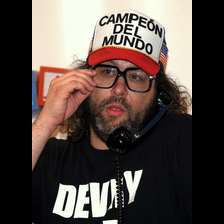

In [35]:
item[0]

In [37]:
item[1].shape

torch.Size([3, 224, 224])

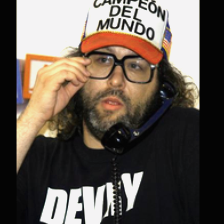

In [42]:
tensor_to_pil(item[1])

### Dataloader

In [65]:
def dataset_collate(batch):
    images  = []
    targets = []
    for _, arr_img, label in batch:
        images.append(arr_img)
        targets.append(label)
    images  = torch.from_numpy(np.array(images)).type(torch.FloatTensor)
    targets = torch.from_numpy(np.array(targets)).long()
    return images, targets

In [72]:
train_loader = DataLoader(
    train_dataset,
    batch_size=config.batch_size,
    shuffle=True,
    num_workers=config.num_workers,
    pin_memory=config.pin_memory,
    persistent_workers=config.persistent_workers,
    prefetch_factor=config.prefetch_factor,
    collate_fn=dataset_collate,
    # drop_last=True,
)

In [73]:
val_loader = DataLoader(
    val_dataset,
    batch_size=config.batch_size * 2,
    shuffle=False,
    num_workers=config.num_workers,
    pin_memory=config.pin_memory,
    persistent_workers=config.persistent_workers,
    prefetch_factor=config.prefetch_factor,
    collate_fn=dataset_collate,
)

In [74]:
item = next(iter(train_loader))

In [75]:
item[0].shape

torch.Size([32, 3, 224, 224])

In [76]:
item[1].shape

torch.Size([32])

In [77]:
item[1]

tensor([0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0,
        0, 0, 1, 0, 0, 0, 0, 0])